# U-Net : segmentation biomédicale

## 1. 	Configuration de l'environnement


In [ ]:
import os, sys, time, math, random, subprocess, glob
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

QUICK = False
RUN_ABLATION = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (très lent, activer le GPU !)")

class CFG:
    seed = 42

    base_ch = 64
    in_tile, out_tile, pad = 572, 388, 92
    dropout = 0.5
    n_val = 6
    w0, sigma = 10.0, 5.0
    grid, elastic_sigma = 3, 10.0
    iters = 12000
    lr = 1e-3
    lr_min_ratio = 0.05
    momentum = 0.99
    grad_clip = 5.0
    eval_every = 1000
    num_workers = 2

if QUICK:
    CFG.base_ch, CFG.iters, CFG.eval_every, CFG.num_workers = 8, 150, 75, 0

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG.seed)
torch.backends.cudnn.benchmark = True

Device : cuda | Tesla T4


## 2. Préparation des données ISBI 2012



images : (30, 512, 512) | labels : (30, 512, 512) | fraction de cellules : 0.78
val : [8, 9, 15, 17, 23, 27]
mean=0.496 std=0.172


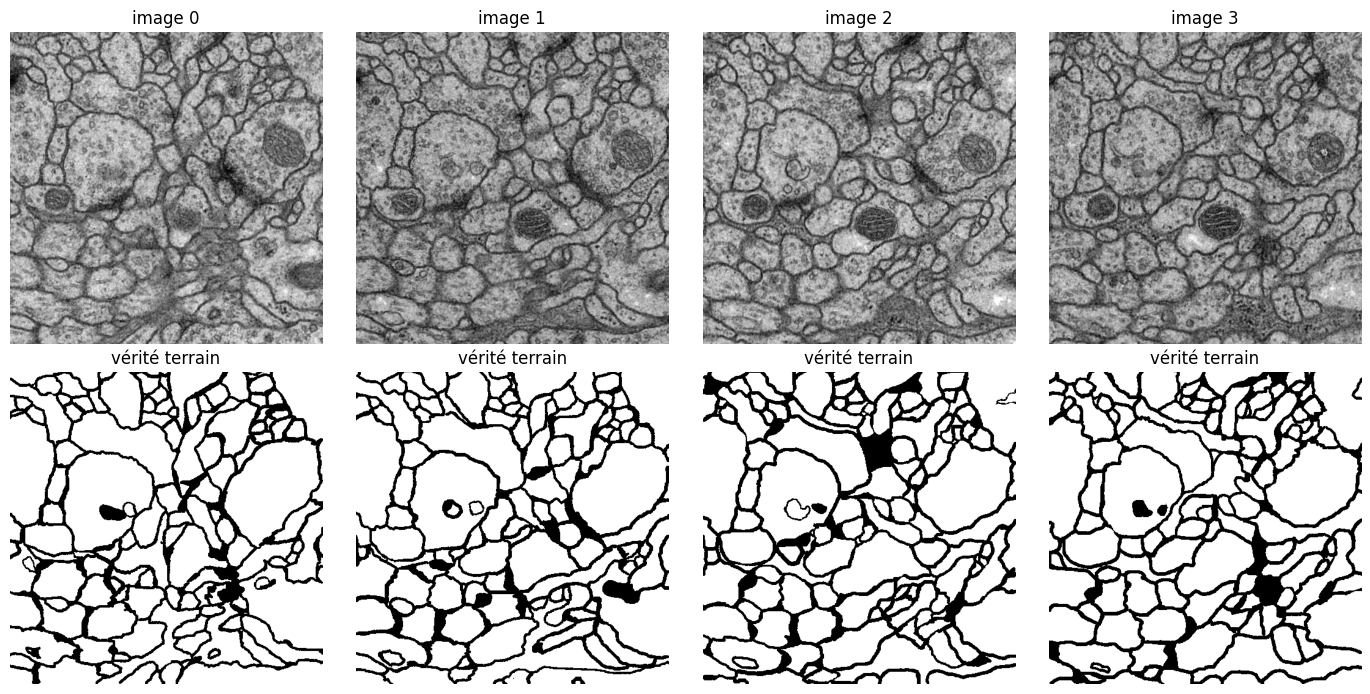

In [ ]:
REPO = "unet"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/zhixuhao/unet.git", REPO], check=True)
ROOT = os.path.join(REPO, "data", "membrane")

def load_png(path):
    return np.array(Image.open(path).convert("L"))

n_total = 30
images = np.stack([load_png(f"{ROOT}/train/image/{i}.png") for i in range(n_total)]).astype(np.float32) / 255.0
labels = np.stack([(load_png(f"{ROOT}/train/label/{i}.png") > 127) for i in range(n_total)]).astype(np.uint8)
print("images :", images.shape, "| labels :", labels.shape, "| fraction de cellules :", round(labels.mean(), 3))
perm = np.random.RandomState(CFG.seed).permutation(n_total)
val_idx, train_idx = np.sort(perm[:CFG.n_val]), np.sort(perm[CFG.n_val:])
print("val :", val_idx.tolist())
tr_imgs, tr_labs = images[train_idx], labels[train_idx]
va_imgs, va_labs = images[val_idx], labels[val_idx]
MEAN, STD = float(tr_imgs.mean()), float(tr_imgs.std())
print(f"mean={MEAN:.3f} std={STD:.3f}")

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j in range(4):
    ax[0, j].imshow(images[j], cmap="gray"); ax[0, j].set_title(f"image {j}"); ax[0, j].axis("off")
    ax[1, j].imshow(labels[j], cmap="gray"); ax[1, j].set_title("vérité terrain"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 3. Calcul des cartes de poids


class weights [membrane, cellule] = [2.27  0.641]
cartes de poids calculées en 31.2s | min=0.64 max=11.50


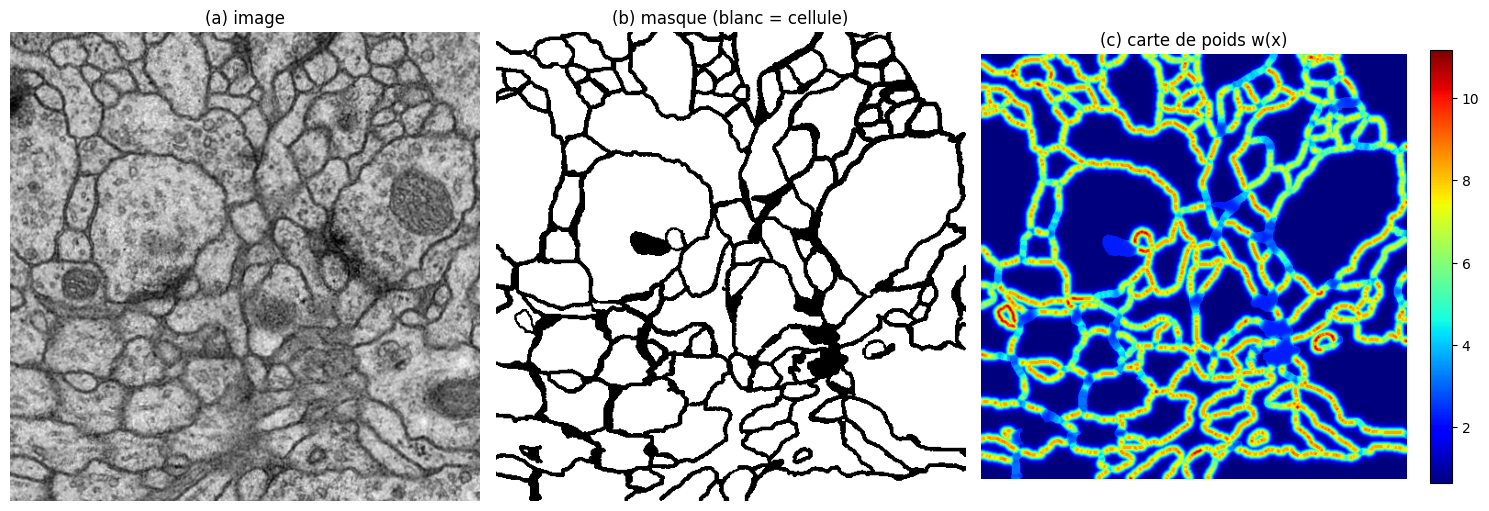

In [ ]:
freq_cell = float(tr_labs.mean())
CLASS_W = np.array([0.5 / (1 - freq_cell), 0.5 / freq_cell], dtype=np.float32)
print("class weights [membrane, cellule] =", CLASS_W.round(3))

def compute_weight_map(label, class_w=CLASS_W, w0=CFG.w0, sigma=CFG.sigma):
    wc = np.where(label == 1, class_w[1], class_w[0]).astype(np.float32)
    cells, n = ndi.label(label == 1)
    d1 = np.full(label.shape, np.inf, np.float32)
    d2 = np.full(label.shape, np.inf, np.float32)
    for k in range(1, n + 1):
        d = ndi.distance_transform_edt(cells != k).astype(np.float32)
        closer = d < d1
        d2 = np.where(closer, d1, np.minimum(d2, d))
        d1 = np.where(closer, d, d1)
    border = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))
    return (wc + border).astype(np.float32)

t0 = time.time()
tr_wmaps = np.stack([compute_weight_map(l) for l in tr_labs])
print(f"cartes de poids calculées en {time.time()-t0:.1f}s | min={tr_wmaps.min():.2f} max={tr_wmaps.max():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(tr_imgs[0], cmap="gray"); ax[0].set_title("(a) image")
ax[1].imshow(tr_labs[0], cmap="gray"); ax[1].set_title("(b) masque (blanc = cellule)")
im = ax[2].imshow(tr_wmaps[0], cmap="jet"); ax[2].set_title("(c) carte de poids w(x)")
for a in ax: a.axis("off")
plt.colorbar(im, ax=ax[2], fraction=0.046); plt.tight_layout(); plt.show()

## 4. Augmentation de données


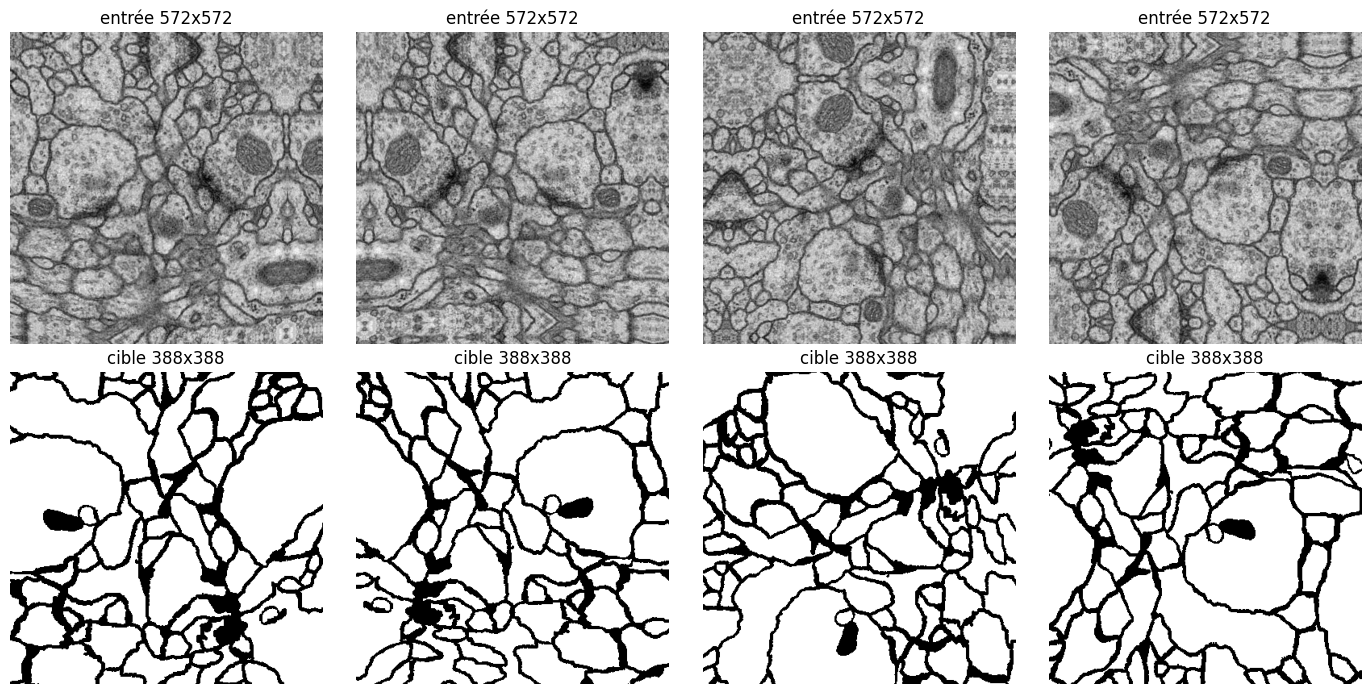

In [ ]:
def elastic_field(h, w, rng, grid=CFG.grid, sigma=CFG.elastic_sigma):
    coarse = rng.normal(0.0, sigma, size=(2, grid, grid))
    out = []
    for c in coarse:
        f = ndi.zoom(c, (h / grid, w / grid), order=3, mode="nearest")
        f = f[:h, :w]
        if f.shape != (h, w):
            f = np.pad(f, ((0, h - f.shape[0]), (0, w - f.shape[1])), mode="edge")
        out.append(f)
    return out  # dy, dx

def elastic_warp(img, lab, wgt, rng, pad=CFG.pad):
    h, w = img.shape
    dy, dx = elastic_field(h, w, rng)
    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    cy, cx = yy + dy, xx + dx
    img_w = ndi.map_coordinates(img, [cy, cx], order=3, mode="reflect")
    s = slice(pad, h - pad)
    lab_w = ndi.map_coordinates(lab, [cy[s, s], cx[s, s]], order=0, mode="reflect")
    wgt_w = ndi.map_coordinates(wgt, [cy[s, s], cx[s, s]], order=1, mode="reflect")
    return img_w.astype(np.float32), lab_w.astype(np.int64), wgt_w.astype(np.float32)

class EMDataset(Dataset):
    def __init__(self, imgs, labs, wmaps, n_samples, use_elastic=True, use_weight_map=True):
        p = CFG.pad
        self.imgs  = [np.pad(a, p, mode="reflect") for a in imgs]
        self.labs  = [np.pad(a, p, mode="reflect").astype(np.float32) for a in labs]
        self.wmaps = [np.pad(a, p, mode="reflect") for a in wmaps]
        self.n, self.use_elastic, self.use_weight_map = n_samples, use_elastic, use_weight_map
    def __len__(self): return self.n
    def __getitem__(self, _):
        rng = np.random.default_rng(int(torch.randint(0, 2**31 - 1, (1,)).item()))
        T, P = CFG.in_tile, CFG.pad
        k = int(rng.integers(len(self.imgs)))
        H = self.imgs[k].shape[0]
        y0, x0 = int(rng.integers(0, H - T + 1)), int(rng.integers(0, H - T + 1))
        sl = (slice(y0, y0 + T), slice(x0, x0 + T))
        img, lab, wgt = self.imgs[k][sl], self.labs[k][sl], self.wmaps[k][sl]
        # rotation (multiples de 90°) + symétrie : groupe diédral
        r, f = int(rng.integers(4)), int(rng.integers(2))
        def dih(a):
            a = np.rot90(a, r)
            return np.ascontiguousarray(a[:, ::-1] if f else a)
        img, lab, wgt = dih(img), dih(lab), dih(wgt)
        if self.use_elastic:
            img, lab, wgt = elastic_warp(img, lab, wgt, rng)
        else:
            s = slice(P, T - P); lab, wgt = lab[s, s].astype(np.int64), wgt[s, s]
        if not self.use_weight_map:
            wgt = np.ones_like(wgt)
        img = img * rng.uniform(0.85, 1.15) + rng.uniform(-0.1, 0.1)
        img = (img - MEAN) / STD
        return (torch.from_numpy(img[None].astype(np.float32)),
                torch.from_numpy(lab.astype(np.int64)),
                torch.from_numpy(wgt.astype(np.float32)))
demo = EMDataset(tr_imgs[:1], tr_labs[:1], tr_wmaps[:1], n_samples=4)
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j in range(4):
    x, y, w = demo[0]
    ax[0, j].imshow(x[0], cmap="gray"); ax[0, j].set_title("entrée 572x572"); ax[0, j].axis("off")
    ax[1, j].imshow(y, cmap="gray"); ax[1, j].set_title("cible 388x388"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 5. Architecture du réseau U-Net

In [ ]:
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3), nn.ReLU(inplace=True))

def center_crop(x, h, w):
    dy, dx = (x.shape[2] - h) // 2, (x.shape[3] - w) // 2
    return x[:, :, dy:dy + h, dx:dx + w]

class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=2, base=64, dropout=0.5):
        super().__init__()
        c = [base * 2 ** i for i in range(5)]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1]),
                                  DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])])
        self.pool = nn.MaxPool2d(2, 2)
        self.bottleneck = DoubleConv(c[3], c[4])
        self.drop = nn.Dropout2d(dropout)
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in (3, 2, 1, 0)])
        self.dec = nn.ModuleList([DoubleConv(c[i + 1], c[i]) for i in (3, 2, 1, 0)])
        self.head = nn.Conv2d(c[0], n_classes, 1)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.normal_(m.weight, 0.0, math.sqrt(2.0 / (m.in_channels * m.kernel_size[0] * m.kernel_size[1])))
            nn.init.zeros_(m.bias)
        elif isinstance(m, nn.ConvTranspose2d):
            nn.init.normal_(m.weight, 0.0, math.sqrt(2.0 / m.in_channels))
            nn.init.zeros_(m.bias)
    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x)
            if i == 3: x = self.drop(x)
            skips.append(x)
            x = self.pool(x)
        x = self.drop(self.bottleneck(x))
        for up, dec, sk in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            x = dec(torch.cat([center_crop(sk, x.shape[2], x.shape[3]), x], dim=1))
        return self.head(x)


net = UNet(base=64)
n_conv = sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in net.modules())
print("couches convolutives (conv + up-conv) :", n_conv, "(article : 23 conv., up-conv comprises dans la Fig. 1)")
print(f"paramètres : {sum(p.numel() for p in net.parameters())/1e6:.1f} M")
net.eval()
with torch.no_grad():
    out = net(torch.zeros(1, 1, 572, 572))
print("entrée (1,1,572,572) -> sortie", tuple(out.shape), " attendu : (1, 2, 388, 388)")
assert out.shape[-2:] == (388, 388)
del net

couches convolutives (conv + up-conv) : 23 (article : 23 conv., up-conv comprises dans la Fig. 1)
paramètres : 31.0 M
entrée (1,1,572,572) -> sortie (1, 2, 388, 388)  attendu : (1, 2, 388, 388)


## 6. Fonction de perte : stratégie *overlap-tile*


In [ ]:
def _dih(a, t):
    a = np.rot90(a, t % 4)
    return a[:, ::-1] if t >= 4 else a
def _dih_inv(a, t):
    if t >= 4: a = a[:, ::-1]
    return np.rot90(a, -(t % 4))

@torch.no_grad()
def _forward_tiles(model, padded, amp):
    T, O = CFG.in_tile, CFG.out_tile
    nH, nW = (padded.shape[0] - 2 * CFG.pad) // O, (padded.shape[1] - 2 * CFG.pad) // O
    out = np.zeros((nH * O, nW * O), np.float32)
    for i in range(nH):
        for j in range(nW):
            tile = padded[i * O:i * O + T, j * O:j * O + T]
            x = torch.from_numpy(np.ascontiguousarray(tile)[None, None]).to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                logits = model(x)
            out[i * O:(i + 1) * O, j * O:(j + 1) * O] = torch.softmax(logits.float(), 1)[0, 1].cpu().numpy()
    return out

def predict_prob(model, img01, tta=False):
    model.eval()
    amp = DEVICE.type == "cuda"
    H, W = img01.shape
    O, P = CFG.out_tile, CFG.pad
    nH, nW = math.ceil(H / O), math.ceil(W / O)
    x = (img01 - MEAN) / STD
    padded = np.pad(x, ((P, P + nH * O - H), (P, P + nW * O - W)), mode="reflect").astype(np.float32)
    if not tta:
        return _forward_tiles(model, padded, amp)[:H, :W]
    acc = 0
    for t in range(8):
        acc = acc + _dih_inv(_forward_tiles(model, np.ascontiguousarray(_dih(padded, t)), amp), t)
    return (acc / 8)[:H, :W]

## 7. Entraînement du modèle


In [ ]:
import copy

THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
MIN_SIZE = 64
def clean_mask(pred, min_size=64):
    out = pred.copy()
    lab, n = ndi.label(out)
    for k in np.where(ndi.sum(out, lab, range(1, n + 1)) < min_size)[0] + 1:
        out[lab == k] = False
    lab, n = ndi.label(~out)
    for k in np.where(ndi.sum(~out, lab, range(1, n + 1)) < min_size)[0] + 1:
        out[lab == k] = True
    return out
def weighted_ce(logits, target, weight):
    ce = F.cross_entropy(logits.float(), target, reduction="none")
    return (ce * weight).mean()



def rand_error(gt_seg, pred_seg):
    m = gt_seg > 0
    g, p = gt_seg[m].astype(np.int64), pred_seg[m].astype(np.int64)
    key = g * (p.max() + 1) + p
    _, cnt = np.unique(key, return_counts=True)
    s_ij = (cnt.astype(np.float64) ** 2).sum()
    a, b = np.bincount(g).astype(np.float64), np.bincount(p).astype(np.float64)
    prec, rec = s_ij / (b ** 2).sum(), s_ij / (a ** 2).sum()
    return 1.0 - 2 * prec * rec / (prec + rec)


def dice_iou(pred, gt):
    inter = float((pred & gt).sum()); union = float((pred | gt).sum())
    s = float(pred.sum() + gt.sum())
    return (2 * inter / s if s else 1.0), (inter / union if union else 1.0)


def metrics_for_image(p_cell, gt):
    gt_b = gt.astype(bool); gt_seg, _ = ndi.label(gt_b)
    res = {}
    for thr in THRESHOLDS:
        pred = clean_mask(p_cell > thr, MIN_SIZE)
        d_c, i_c = dice_iou(pred, gt_b); d_m, i_m = dice_iou(~pred, ~gt_b)
        res[thr] = dict(pixel_error=float((pred != gt_b).mean()), rand_error=rand_error(gt_seg, ndi.label(pred)[0]),
                        dice_cell=d_c, iou_cell=i_c, dice_mem=d_m, iou_mem=i_m)
    return res


def evaluate(model, imgs, labs, tta=False):
    probs = [predict_prob(model, im, tta=tta) for im in imgs]
    per_img = [metrics_for_image(p, l) for p, l in zip(probs, labs)]
    table = {thr: {k: float(np.mean([r[thr][k] for r in per_img])) for k in per_img[0][thr]} for thr in THRESHOLDS}
    summary = dict(table[0.5])
    summary["pixel_error_best"] = min(table[t]["pixel_error"] for t in THRESHOLDS)
    summary["rand_error_best"] = min(table[t]["rand_error"] for t in THRESHOLDS)
    return summary, probs

def train_model(tag="U-Net", use_weight_map=True, use_elastic=True, iters=None, seed=CFG.seed):
    iters = iters or CFG.iters
    seed_everything(seed)
    model = UNet(base=CFG.base_ch, dropout=CFG.dropout).to(DEVICE)
    ds = EMDataset(tr_imgs, tr_labs, tr_wmaps, n_samples=iters, use_elastic=use_elastic, use_weight_map=use_weight_map)
    loader = DataLoader(ds, batch_size=1, num_workers=CFG.num_workers, pin_memory=DEVICE.type == "cuda",
                        persistent_workers=CFG.num_workers > 0)
    opt = torch.optim.SGD(model.parameters(), lr=CFG.lr, momentum=CFG.momentum)


    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)

    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = dict(it=[], loss=[], val_it=[], val_dice=[], val_pixel_error=[], val_rand_error=[])
    run, t0 = [], time.time()

    for it, (x, y, w) in enumerate(loader, 1):
        lr = CFG.lr * (CFG.lr_min_ratio + (1 - CFG.lr_min_ratio) * 0.5 * (1 + math.cos(math.pi * it / iters)))
        for g in opt.param_groups:
            g["lr"] = lr
        model.train()
        x, y, w = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True), w.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        loss = weighted_ce(logits, y, w)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
        scaler.step(opt); scaler.update()

        with torch.no_grad():
            d = min(0.999, (1 + it) / (10 + it))
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.mul_(d).add_(pm.detach(), alpha=1 - d)

        run.append(loss.item())
        if it % 50 == 0:
            hist["it"].append(it); hist["loss"].append(float(np.mean(run[-50:])))
        if it % CFG.eval_every == 0 or it == iters:
            s, _ = evaluate(ema, va_imgs, va_labs, tta=False)
            hist["val_it"].append(it); hist["val_dice"].append(s["dice_cell"])
            hist["val_pixel_error"].append(s["pixel_error"]); hist["val_rand_error"].append(s["rand_error"])
            print(f"[{tag}] it {it:5d}/{iters} | loss {np.mean(run[-200:]):.4f} | val pixel err {s['pixel_error']:.4f} "
                  f"| val Rand err {s['rand_error']:.4f} | Dice(cell) {s['dice_cell']:.4f} | {time.time()-t0:.0f}s", flush=True)
    return ema, hist

## 8. Évaluation des performances


In [ ]:
model, hist = train_model(tag="U-Net complet")
torch.save(model.state_dict(), "unet_isbi2012.pt")

[U-Net complet] it   500/6000 | loss 1.1773 | val pixel err 0.1406 | val Rand err 0.4839 | Dice(cell) 0.9076 | 79s
[U-Net complet] it  1000/6000 | loss 1.0371 | val pixel err 0.1365 | val Rand err 0.3690 | Dice(cell) 0.9096 | 157s
[U-Net complet] it  1500/6000 | loss 0.9681 | val pixel err 0.1249 | val Rand err 0.3174 | Dice(cell) 0.9174 | 240s
[U-Net complet] it  2000/6000 | loss 0.9438 | val pixel err 0.1155 | val Rand err 0.2506 | Dice(cell) 0.9241 | 316s
[U-Net complet] it  2500/6000 | loss 0.9171 | val pixel err 0.1075 | val Rand err 0.2134 | Dice(cell) 0.9295 | 394s
[U-Net complet] it  3000/6000 | loss 0.9027 | val pixel err 0.1052 | val Rand err 0.1946 | Dice(cell) 0.9309 | 469s
[U-Net complet] it  3500/6000 | loss 0.8912 | val pixel err 0.1021 | val Rand err 0.1829 | Dice(cell) 0.9330 | 546s
[U-Net complet] it  4000/6000 | loss 0.8730 | val pixel err 0.1011 | val Rand err 0.1827 | Dice(cell) 0.9336 | 623s
[U-Net complet] it  4500/6000 | loss 0.8701 | val pixel err 0.0990 | val 

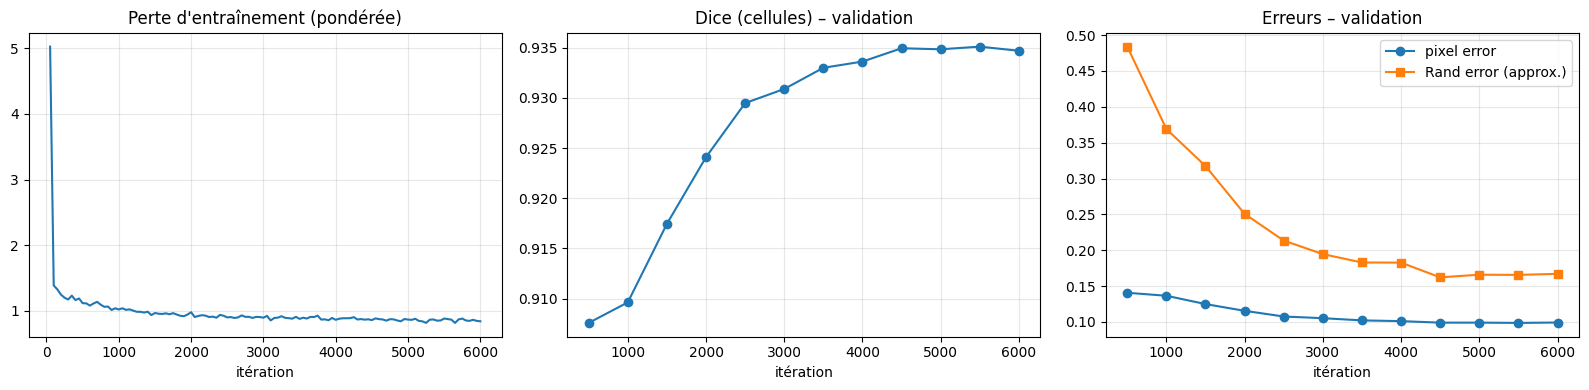

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist["it"], hist["loss"]); ax[0].set_title("Perte d'entraînement (pondérée)"); ax[0].set_xlabel("itération")
ax[1].plot(hist["val_it"], hist["val_dice"], "o-"); ax[1].set_title("Dice (cellules) – validation"); ax[1].set_xlabel("itération")
ax[2].plot(hist["val_it"], hist["val_pixel_error"], "o-", label="pixel error")
ax[2].plot(hist["val_it"], hist["val_rand_error"], "s-", label="Rand error (approx.)")
ax[2].set_title("Erreurs – validation"); ax[2].set_xlabel("itération"); ax[2].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
final_tta, probs_tta = evaluate(model, va_imgs, va_labs, tta=True)
final_plain, _ = evaluate(model, va_imgs, va_labs, tta=False)
res = pd.DataFrame({"sans TTA": final_plain, "avec TTA (x8)": final_tta}).T
print(res[["pixel_error", "pixel_error_best", "rand_error", "rand_error_best", "dice_cell", "iou_cell", "dice_mem", "iou_mem"]].round(4).to_string())

               pixel_error  pixel_error_best  rand_error  rand_error_best  dice_cell  iou_cell  dice_mem  iou_mem
sans TTA            0.0992            0.0908      0.1670           0.1307     0.9347    0.8776    0.7917   0.6554
avec TTA (x8)       0.0971            0.0894      0.1595           0.1231     0.9361    0.8802    0.7953   0.6604


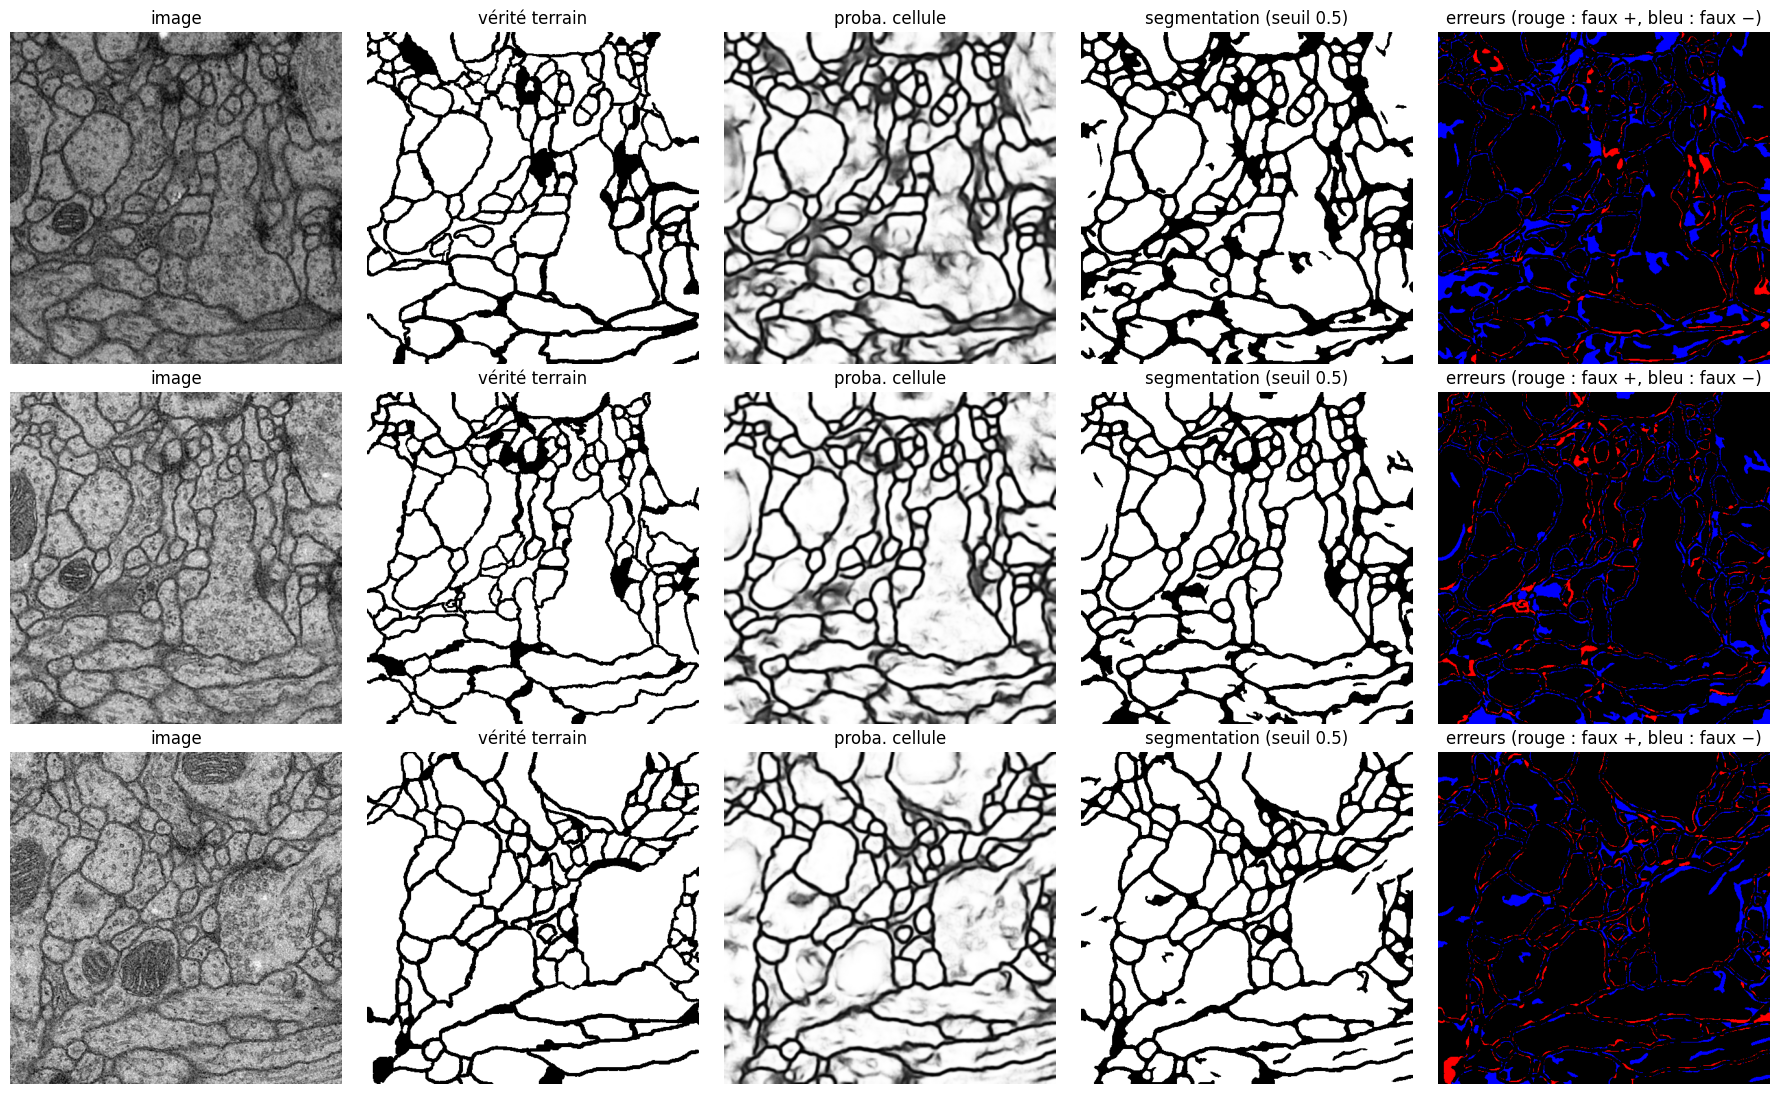

In [22]:
fig, ax = plt.subplots(3, 5, figsize=(18, 11))
for r in range(3):
    img, gt, p = va_imgs[r], va_labs[r], probs_tta[r]
    pred = clean_mask(p > 0.5, MIN_SIZE)
    ax[r, 0].imshow(img, cmap="gray"); ax[r, 0].set_title("image")
    ax[r, 1].imshow(gt, cmap="gray"); ax[r, 1].set_title("vérité terrain")
    ax[r, 2].imshow(p, cmap="gray"); ax[r, 2].set_title("proba. cellule")
    ax[r, 3].imshow(pred, cmap="gray"); ax[r, 3].set_title("segmentation (seuil 0.5)")
    err = np.zeros((*gt.shape, 3)); err[pred & (gt == 0)] = [1, 0, 0]; err[~pred & (gt == 1)] = [0, 0, 1]
    ax[r, 4].imshow(err); ax[r, 4].set_title("erreurs (rouge : faux +, bleu : faux −)")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

## 9. Étude d'ablation



In [ ]:
rows = {"U-Net complet": final_plain}
if RUN_ABLATION:
    m_nw, _ = train_model(tag="sans carte de poids", use_weight_map=False)
    rows["sans carte de poids"], _ = evaluate(m_nw, va_imgs, va_labs, tta=False); del m_nw
    m_ne, _ = train_model(tag="sans déformation élastique", use_elastic=False)
    rows["sans déformation élastique"], _ = evaluate(m_ne, va_imgs, va_labs, tta=False); del m_ne
abl = pd.DataFrame(rows).T[["pixel_error", "rand_error", "rand_error_best", "dice_cell", "iou_cell"]]
print(abl.round(4).to_string())

[sans carte de poids] it   500/6000 | loss 0.3776 | val pixel err 0.1265 | val Rand err 0.8972 | Dice(cell) 0.9225 | 81s
[sans carte de poids] it  1000/6000 | loss 0.3218 | val pixel err 0.1143 | val Rand err 0.7887 | Dice(cell) 0.9290 | 160s
[sans carte de poids] it  1500/6000 | loss 0.2938 | val pixel err 0.1082 | val Rand err 0.6503 | Dice(cell) 0.9320 | 237s
[sans carte de poids] it  2000/6000 | loss 0.2699 | val pixel err 0.1024 | val Rand err 0.5423 | Dice(cell) 0.9357 | 313s
[sans carte de poids] it  2500/6000 | loss 0.2376 | val pixel err 0.0974 | val Rand err 0.4259 | Dice(cell) 0.9383 | 389s
[sans carte de poids] it  3000/6000 | loss 0.2361 | val pixel err 0.0938 | val Rand err 0.3477 | Dice(cell) 0.9403 | 465s
[sans carte de poids] it  3500/6000 | loss 0.2182 | val pixel err 0.0920 | val Rand err 0.3165 | Dice(cell) 0.9413 | 541s
[sans carte de poids] it  4000/6000 | loss 0.2186 | val pixel err 0.0905 | val Rand err 0.2858 | Dice(cell) 0.9421 | 619s
[sans carte de poids] it 

## 10. Prédiction et comparaison des résultats

30 images de test


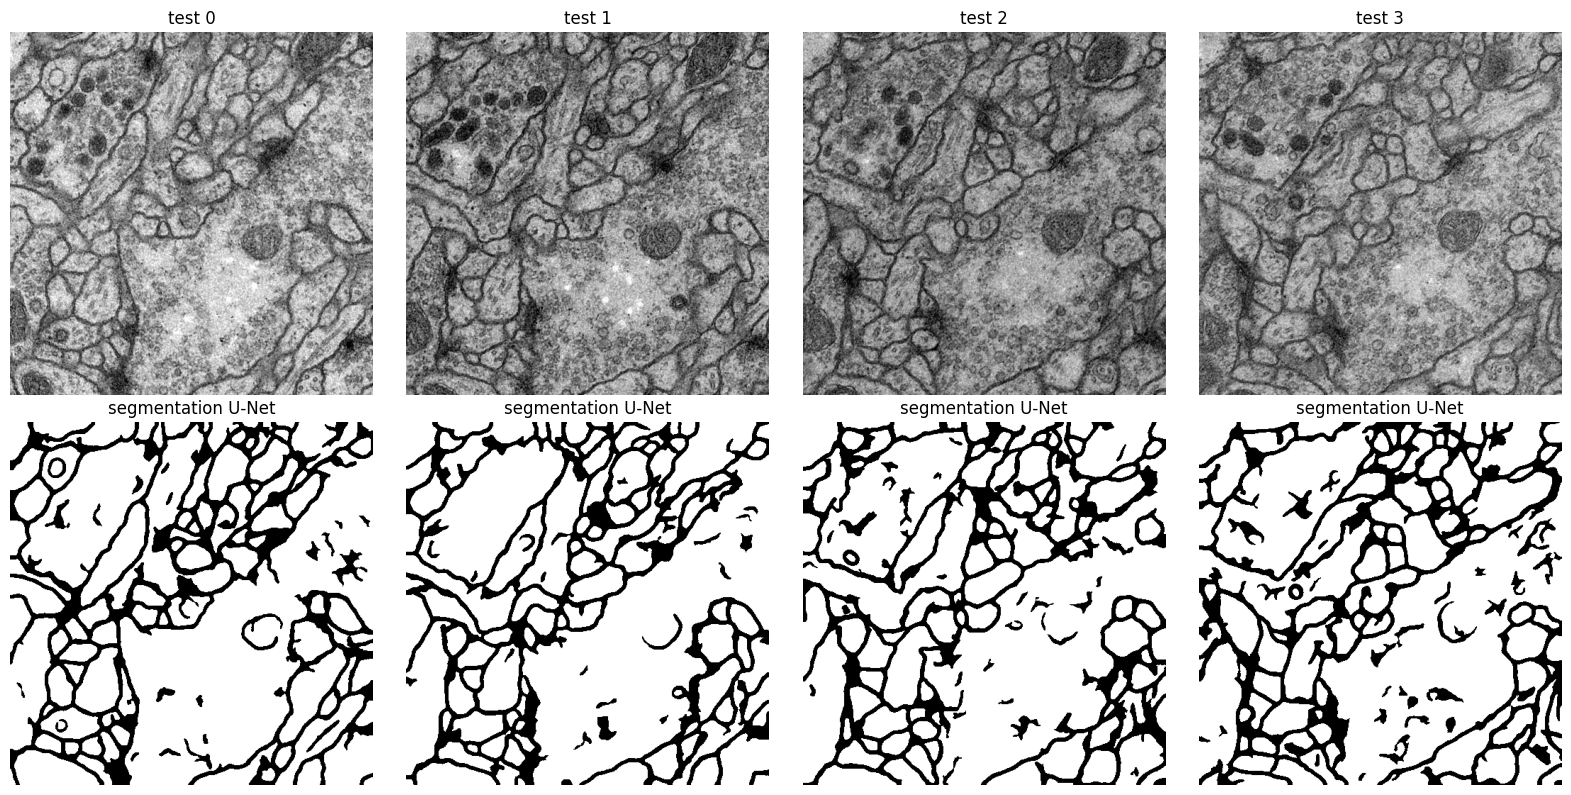

cartes de probabilité enregistrées dans predictions_test/


In [23]:
test_files = sorted([f for f in glob.glob(f"{ROOT}/test/*.png") if "_predict" not in f],
                    key=lambda p: int(os.path.basename(p).split(".")[0]))
os.makedirs("predictions_test", exist_ok=True)
print(len(test_files), "images de test")
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j, f in enumerate(test_files):
    img = load_png(f).astype(np.float32) / 255.0
    p = predict_prob(model, img, tta=True)
    Image.fromarray((p * 255).astype(np.uint8)).save(f"predictions_test/{os.path.basename(f)}")
    if j < 4:
        ax[0, j].imshow(img, cmap="gray"); ax[0, j].set_title(f"test {j}"); ax[0, j].axis("off")
        ax[1, j].imshow(clean_mask(p > 0.5, MIN_SIZE), cmap="gray"); ax[1, j].set_title("segmentation U-Net"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()
print("cartes de probabilité enregistrées dans predictions_test/")